# Entregable II — Entrenamiento y evaluación de modelos (30 %)

**Proyecto:** Predicción de la intención de compra de usuarios en línea mediante aprendizaje supervisado.
**Curso:** Modelos y Simulación de Sistemas II — Universidad de Antioquia.

Este notebook reproduce la sección 1 del Entregable II: la configuración experimental y los
resultados del entrenamiento y la evaluación de cinco familias de modelos
(regresión logística, k-NN, Random Forest, red neuronal MLP y SVM) sobre el
*Online Shoppers Purchasing Intention Dataset* (UCI #468).

Toda la lógica vive en `src/proyecto_ml.py`, de modo que el notebook, los scripts y el informe
comparten exactamente el mismo código. Ejecute las celdas en orden.

> **Nota de tiempo:** el ajuste completo de hiperparámetros y el bootstrap tardan alrededor de
> 12 minutos. Establezca `RECALCULAR = True` para recomputar todo desde el CSV; con `False` se
> cargan los resultados ya guardados en `resultados/`.


In [1]:
import os
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ / "src"))

RECALCULAR = False  # True para reentrenar todos los modelos desde cero

import json
import pandas as pd
from IPython.display import Image, display

pd.set_option("display.width", 200)
print("Directorio de trabajo:", RAIZ)
print("Recalcular desde cero:", RECALCULAR)


Directorio de trabajo: C:\proyectos-git\proyecto-modelos-2-prediccion-intencion-compra
Recalcular desde cero: False


## 1. Auditoría del conjunto de datos

Se verifican dimensiones, valores faltantes, duplicados exactos y balance de clases antes de
particionar. Los duplicados exactos se eliminan para evitar que una misma sesión aparezca a la
vez en entrenamiento y prueba.


In [2]:
from proyecto_ml import auditar, cargar_datos, tabla_auditoria

df = cargar_datos()
aud = auditar(df)
print(json.dumps({k: aud[k] for k in
      ["filas", "columnas", "nulos_totales", "duplicados_exactos",
       "clases", "proporcion_compra"]}, ensure_ascii=False, indent=2))
tabla_auditoria(df)


{
  "filas": 12330,
  "columnas": 18,
  "nulos_totales": 0,
  "duplicados_exactos": 125,
  "clases": {
    "False": 10422,
    "True": 1908
  },
  "proporcion_compra": 0.15474452554744525
}


,variable,tipo,n_unicos,min,max,media,nulos,categoria_mas_frecuente,frecuencia_max
0,Administrative,numerica,27,0.0,27.000000,2.315166,0,NaN,NaN
1,Administrative_Duration,numerica,3335,0.0,3398.750000,80.818611,0,NaN,NaN
2,Informational,numerica,17,0.0,24.000000,0.503569,0,NaN,NaN
3,Informational_Duration,numerica,1258,0.0,2549.375000,34.472398,0,NaN,NaN
4,ProductRelated,numerica,311,0.0,705.000000,31.731468,0,NaN,NaN
5,ProductRelated_Duration,numerica,9551,0.0,63973.522230,1194.746220,0,NaN,NaN
6,BounceRates,numerica,1872,0.0,0.200000,0.022191,0,NaN,NaN
7,ExitRates,numerica,4777,0.0,0.200000,0.043073,0,NaN,NaN
8,PageValues,numerica,2704,0.0,361.763742,5.889258,0,NaN,NaN
9,Month,categorica,10,NaN,NaN,NaN,0,May,3364.0


## 2. Particiones de entrenamiento, validación y prueba

Partición estratificada 60/20/20 sobre el conjunto depurado. El test se mantiene aislado
hasta la evaluación final.


In [3]:
from proyecto_ml import particionar, resumen_particiones

df_u, X, y, itr, iva, ite = particionar(df)
resumen_particiones(y, itr, iva, ite)


,particion,n,positivos,negativos,proporcion_compra
0,Entrenamiento,7323,1145,6178,0.156357
1,Validacion,2441,381,2060,0.156084
2,Test,2441,382,2059,0.156493


## 3. Diseño experimental: preprocesamiento y mallas de hiperparámetros

El preprocesamiento se encapsula en un `ColumnTransformer` dentro de un `Pipeline`, de modo que
la imputación, la transformación `log1p` y el escalado se ajustan **solo con los datos de
entrenamiento de cada fold**. La comparación con y sin `log1p` se trata como un hiperparámetro
más de la malla.


In [4]:
from proyecto_ml import construir_modelos, contar_combinaciones

_, mallas = construir_modelos()
for modelo, malla in mallas.items():
    print(f"--- {modelo} ---")
    for k, v in malla.items():
        print(f"    {k}: {v}")
print()
contar_combinaciones(mallas)


--- Regresion_logistica ---
    pre__num__log__usar_log: [True, False]
    clf__C: [0.01, 0.1, 1, 10]
    clf__class_weight: [None, 'balanced']
--- kNN ---
    pre__num__log__usar_log: [True, False]
    clf__n_neighbors: [5, 15, 31]
    clf__weights: ['uniform', 'distance']
    clf__p: [1, 2]
--- RandomForest ---
    pre__num__log__usar_log: [True, False]
    clf__max_depth: [None, 12]
    clf__min_samples_leaf: [1, 5]
    clf__max_features: ['sqrt', 0.5]
    clf__class_weight: [None, 'balanced']
--- MLP ---
    pre__num__log__usar_log: [True, False]
    clf__hidden_layer_sizes: [(32,), (64,), (64, 32)]
    clf__alpha: [0.0001, 0.01]
    clf__learning_rate_init: [0.001, 0.01]
--- SVM ---
    pre__num__log__usar_log: [True, False]
    clf__kernel: ['linear', 'rbf']
    clf__C: [0.1, 1, 10]
    clf__gamma: ['scale', 0.01]
    clf__class_weight: [None, 'balanced']



,modelo,combinaciones
0,Regresion_logistica,16
1,kNN,24
2,RandomForest,32
3,MLP,24
4,SVM,48


## 4. Entrenamiento y evaluación

Cada familia se ajusta con `GridSearchCV` (validación cruzada estratificada de 5 folds,
`scoring=average_precision`). Después se evalúan los cinco finalistas en entrenamiento,
validación y prueba, se calculan intervalos de confianza por bootstrap estratificado, se mide la
sensibilidad al retirar `PageValues` y se realiza la ablación de `SpecialDay`.


In [5]:
if RECALCULAR:
    import entrenar
    entrenar.main()
    import figuras
    figuras.main()
else:
    print("Se cargan los resultados guardados en resultados/.")
    print("Establezca RECALCULAR = True para reentrenar desde el CSV.")


Se cargan los resultados guardados en resultados/.
Establezca RECALCULAR = True para reentrenar desde el CSV.


## 5. Resultados: mejor configuración y efecto de los hiperparámetros


In [6]:
mejores = pd.read_csv("resultados/mejores_configuraciones.csv")
mejores


,modelo,mejores_hiperparametros,AP_CV,std_CV,tiempo_seg
0,RandomForest,"{""clf__class_weight"": null, ""clf__max_depth"": ...",0.753151,0.034965,52.317732
1,MLP,"{""clf__alpha"": 0.0001, ""clf__hidden_layer_size...",0.729354,0.039118,13.687620
2,SVM,"{""clf__C"": 10, ""clf__class_weight"": null, ""clf...",0.726585,0.033579,148.881208
3,kNN,"{""clf__n_neighbors"": 31, ""clf__p"": 2, ""clf__we...",0.712433,0.026955,10.329879
4,Regresion_logistica,"{""clf__C"": 0.1, ""clf__class_weight"": null, ""pr...",0.689679,0.031968,7.087162


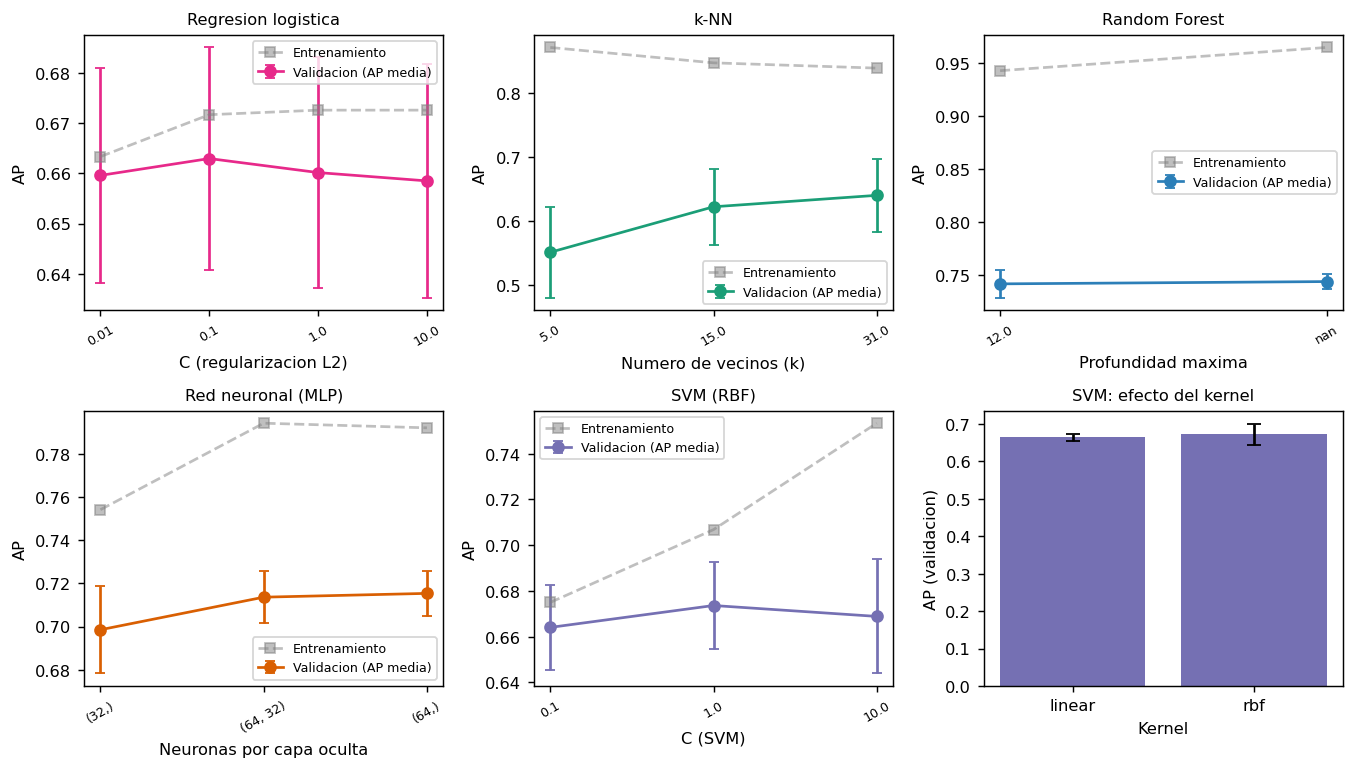

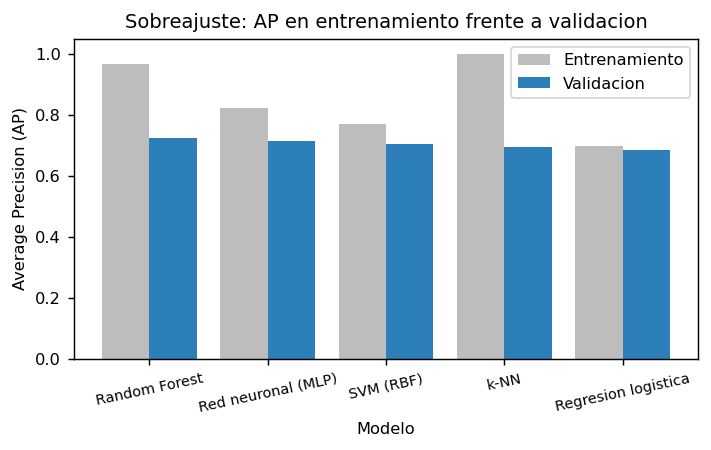

In [7]:
display(Image(filename="resultados/figuras/fig03_efecto_hiperparametros.png"))
display(Image(filename="resultados/figuras/fig04_train_vs_validacion.png"))


## 6. Desempeño en entrenamiento, validación y prueba

Los intervalos de confianza del 95 % se estimaron con bootstrap estratificado (2000 réplicas).


In [8]:
met = pd.read_csv("resultados/metricas_particiones.csv")
ic = pd.read_csv("resultados/metricas_intervalos_confianza.csv")

tabla = met.pivot_table(index="modelo", columns="particion",
                        values=["AP", "ROC_AUC", "F1", "precision", "recall",
                                "balanced_accuracy"]).round(4)
tabla


AP                               F1                          ROC_AUC                    balanced_accuracy                        precision                     \
particion           entrenamiento    test validacion entrenamiento    test validacion entrenamiento    test validacion     entrenamiento    test validacion entrenamiento    test validacion   
modelo                                                                                                                                                                                         
MLP                        0.8228  0.7377     0.7134        0.7117  0.6504     0.6408        0.9558  0.9270     0.9202            0.8097  0.7747     0.7703        0.7816  0.7220     0.7079   
RandomForest               0.9661  0.7486     0.7247        0.8412  0.5904     0.5890        0.9924  0.9242     0.9168            0.8649  0.7225     0.7218        0.9905  0.8054     0.8045   
Regresion_logistica        0.6987  0.6956     0.6841        0.6227  0.6213     0.6445        0.9194  0.9110     0.9123            0.7555  0.7545     0.7713        0.7141  0.7143     0.7170   
SVM                        0.7703  0.7287     0.7049        0.6870  0.6494     0.6322        0.9253  0.9020     0.8960            0.7963  0.7736     0.7657        0.7544  0.7235     0.6984   
kNN                        1.0000  0.7050     0.6936        1.0000  0.5976     0.5927        1.0000  0.9046     0.9037            1.0000  0.7398     0.7360        1.0000  0.7007     0.7040   

                           recall                     
particion           entrenamiento    test validacion  
modelo                                                
MLP                        0.6533  0.5916     0.5853  
RandomForest               0.7310  0.4660     0.4646  
Regresion_logistica        0.5520  0.5497     0.5853  
SVM                        0.6306  0.5890     0.5774  
kNN                        1.0000  0.5209     0.5118

In [9]:
ic[(ic.metrica == "AP")].round(4)


,modelo,particion,metrica,media_bootstrap,ic_inferior,ic_superior
0,Regresion_logistica,entrenamiento,AP,0.6992,0.6720,0.7251
7,Regresion_logistica,validacion,AP,0.6866,0.6392,0.7342
14,Regresion_logistica,test,AP,0.6975,0.6541,0.7396
21,kNN,entrenamiento,AP,1.0000,1.0000,1.0000
28,kNN,validacion,AP,0.6947,0.6539,0.7354
35,kNN,test,AP,0.7065,0.6634,0.7465
42,RandomForest,entrenamiento,AP,0.9661,0.9600,0.9714
49,RandomForest,validacion,AP,0.7260,0.6855,0.7648
56,RandomForest,test,AP,0.7494,0.7115,0.7848
63,MLP,entrenamiento,AP,0.8229,0.8031,0.8410


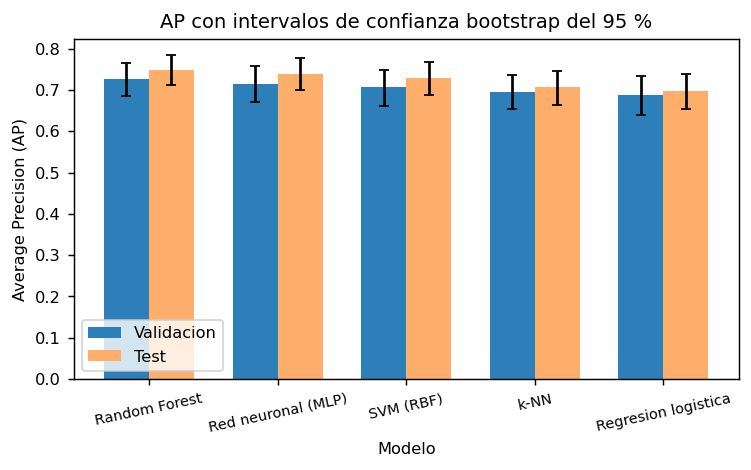

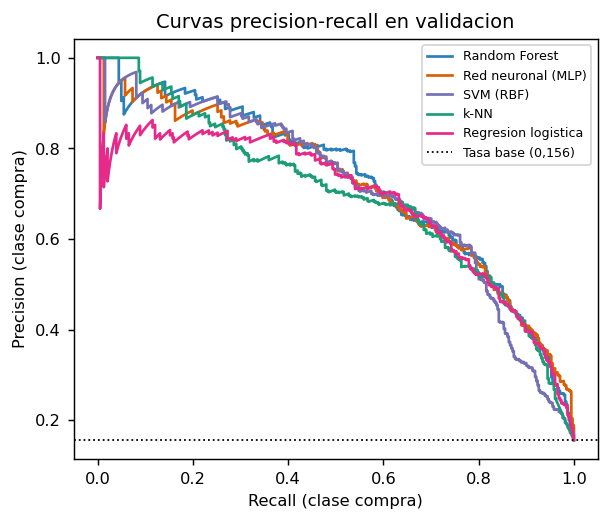

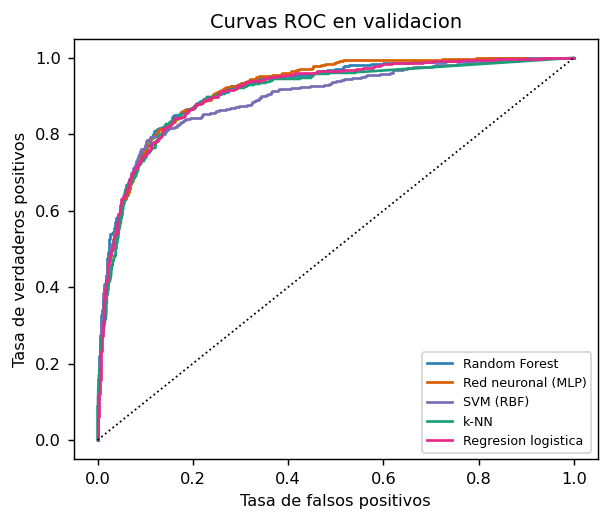

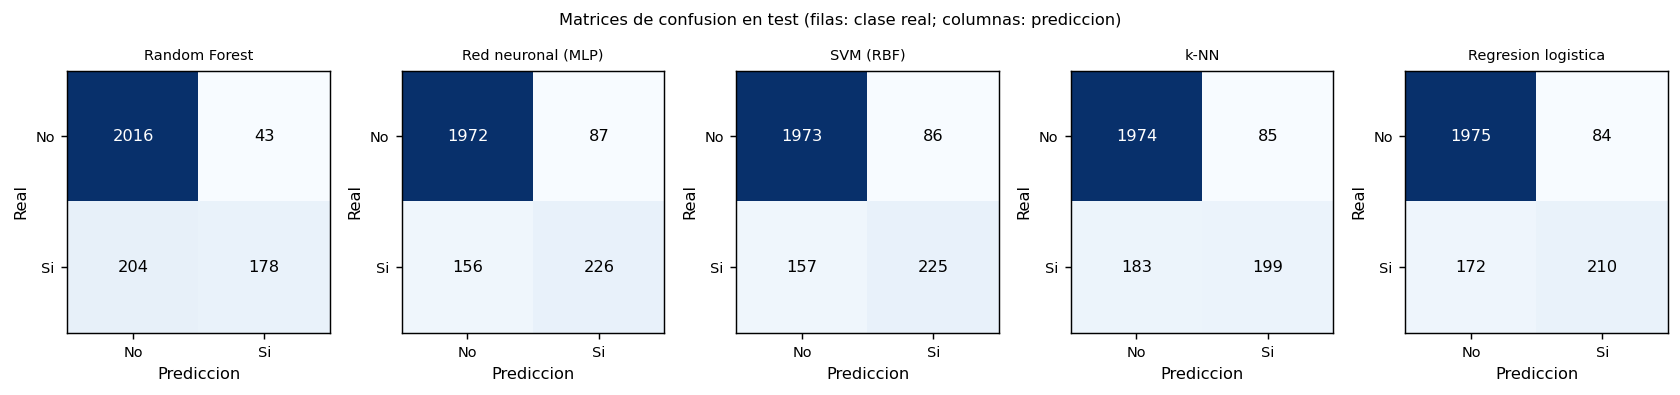

In [10]:
display(Image(filename="resultados/figuras/fig08_ap_intervalos.png"))
display(Image(filename="resultados/figuras/fig05_curvas_pr.png"))
display(Image(filename="resultados/figuras/fig06_curvas_roc.png"))
display(Image(filename="resultados/figuras/fig07_matrices_confusion_test.png"))


## 7. Sensibilidad a `PageValues` y tratamiento de `SpecialDay`


In [11]:
print("Sensibilidad sin PageValues (validación):")
display(pd.read_csv("resultados/comparacion_pagevalues.csv").round(4))
print("Equivalencia numérica/ordinal de SpecialDay:")
print(json.loads(Path("resultados/specialday_equivalencia.json").read_text(encoding="utf-8")))
print("Ablación de SpecialDay (validación):")
display(pd.read_csv("resultados/comparacion_specialday.csv").round(4))


Sensibilidad sin PageValues (validación):


,modelo,AP_con_PageValues,AP_sin_PageValues,delta_AP,ROC_AUC_con,ROC_AUC_sin
0,Regresion_logistica,0.6841,0.3345,0.3496,0.9123,0.7616
1,kNN,0.6936,0.3177,0.3759,0.9037,0.7421
2,RandomForest,0.7247,0.3852,0.3395,0.9168,0.7845
3,MLP,0.7134,0.3273,0.3861,0.9202,0.7582
4,SVM,0.7049,0.3403,0.3646,0.8960,0.7685


Equivalencia numérica/ordinal de SpecialDay:
{'valores_unicos': [0.0, 0.2, 0.4, 0.6, 0.8, 1.0], 'correlacion_representaciones_escaladas': 1.0, 'conclusion': 'SpecialDay es equiespaciado; la codificacion ordinal es una transformacion afín de la numerica, por lo que tras estandarizar ambas representaciones son identicas.'}
Ablación de SpecialDay (validación):


,modelo,AP_con_SpecialDay,AP_sin_SpecialDay,delta_AP
0,Regresion_logistica,0.6841,0.6845,-0.0004
1,kNN,0.6936,0.6971,-0.0035
2,RandomForest,0.7247,0.7250,-0.0003
3,MLP,0.7134,0.7164,-0.0030
4,SVM,0.7049,0.7033,0.0016


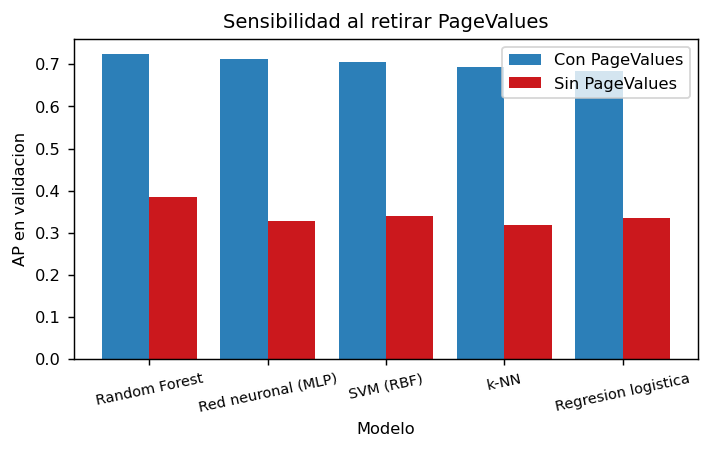

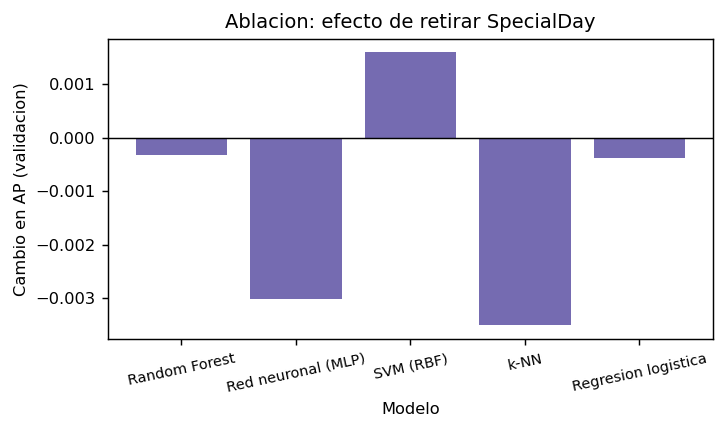

In [12]:
display(Image(filename="resultados/figuras/fig09_sensibilidad_pagevalues.png"))
display(Image(filename="resultados/figuras/fig10_ablacion_specialday.png"))


## 8. Conclusiones

- **Random Forest** obtiene el mejor AP tanto en validación como en prueba, aunque con mayor
  sobreajuste y menor recall con el umbral nativo.
- La **red neuronal** y **SVM** ofrecen un compromiso distinto, con mayor recuperación de la
  clase minoritaria.
- **`PageValues` concentra gran parte de la señal predictiva**: al retirarla el AP cae más de
  30 puntos, lo que impide afirmar un escenario de predicción en tiempo real.
- El tratamiento numérico y el ordinal de **`SpecialDay`** son equivalentes y su contribución es
  marginal.
- Todas las decisiones de preprocesamiento y selección se tomaron sin usar el conjunto de prueba.


In [13]:
# Genera el informe DOCX y PDF a partir de los resultados guardados
import informe
informe.main()
try:
    informe.convertir_pdf(informe.SALIDA_DOCX, informe.SALIDA_PDF)
except Exception as e:
    print("No se pudo convertir a PDF:", e)


DOCX guardado: C:\proyectos-git\proyecto-modelos-2-prediccion-intencion-compra\informe_entregable_II.docx


No se pudo convertir a PDF: Open.SaveAs
